# Genotype Diagrams

In [1]:
## CONFIG ##

import importlib
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# Reload configs on each run.
import config
import sbol
importlib.reload(config)
importlib.reload(sbol)

# sbol.DPI matches PNG_DPI
sys.path.insert(0, str(Path("../nb").resolve()))
import analyse_pr_config
importlib.reload(analyse_pr_config)
from analyse_pr_config import FIGURE_DPI, PNG_DPI

assert sbol.DPI == PNG_DPI, (sbol.DPI, PNG_DPI)


## PLOTTING ##

plt.rcParams["figure.dpi"] = FIGURE_DPI
plt.rcParams["savefig.dpi"] = sbol.DPI


## OUTPUT ##

SBOL_DIR = config.OUT_DIR / "sbol"
CLASSIFY_SBOL_DIR = config.OUT_DIR / "classify_sbol"
BARS_SBOL_DIR = config.OUT_DIR / "bars_sbol"
CLASSIFY_FLOW_SBOL_DIR = config.OUT_DIR / "classify_flow_sbol"
for directory in (SBOL_DIR, CLASSIFY_SBOL_DIR, BARS_SBOL_DIR, CLASSIFY_FLOW_SBOL_DIR):
    directory.mkdir(parents=True, exist_ok=True)

# the charts the strips are composited onto, each at its own figure width
CLASSIFY_DIR = Path("../nb/out/analyse_pr_classify")
BARS_DIR = Path("../nb/out/analyse_pr_synthrate_bars")
# the flow densities, drawn at CLASSIFY_WIDTH_IN so they stack on the classify chart
FLOW_DIR = Path("../nb/out/analyse_flow")

# the circuit the preview at the end follows
CIRCUIT = 75

In [2]:
# every filtered barcode, the invalid assemblies included
genotypes = pd.read_csv(config.FILTERED_CSV)

# Every part must have a glyph
missing = sorted(set(config.PART_BP) - set(sbol.GLYPH))
assert not missing, missing

# Zero-padded, matching the chart PNGs
genotypes["stem"] = [f"circuit_{int(circuit.split('_')[1]):02d}"
                     for circuit in genotypes["circuit"]]
genotypes["parts"] = [circuit_parts.split("-") + list(sbol.DOWNSTREAM)
                      for circuit_parts in genotypes["circuit_parts"]]

print(f"{len(genotypes)} circuits, {genotypes.valid.sum()} valid, "
      f"{len(set(config.PART_BP))} parts all drawable")

68 circuits, 58 valid, 16 parts all drawable


In [3]:
sizes = {}
for row in genotypes.itertuples():
    figure = sbol.figure(row.parts, sbol.CLASSIFY_WIDTH_IN)
    path = SBOL_DIR / f"{row.stem}_sbol.png"
    figure.savefig(path)
    plt.close(figure)
    sizes[row.stem] = Image.open(path).size

widths = {size[0] for size in sizes.values()}
heights = sorted(size[1] for size in sizes.values())
print(f"{SBOL_DIR}: {len(sizes)} PNGs, {widths} px wide, {heights[0]}-{heights[-1]} px tall")

/home/ado/mscr/dev/seq/out/sbol: 68 PNGs, {2550} px wide, 256-742 px tall


## Composites

In [4]:
# Pass dpi so LaTeX gets the physical size
written, skipped = 0, []
for row in genotypes.itertuples():
    chart = CLASSIFY_DIR / f"{row.stem}.png"
    # Skip circuits with no classify chart
    if not chart.exists():
        skipped.append(row.stem)
        continue
    stacked = sbol.composite(row.parts, chart, sbol.CLASSIFY_WIDTH_IN)
    stacked.save(CLASSIFY_SBOL_DIR / f"classify_{row.stem}_sbol.png", dpi=(sbol.DPI, sbol.DPI))
    written += 1

print(f"{CLASSIFY_SBOL_DIR}: {written} composites, {len(skipped)} skipped {skipped}")

/home/ado/mscr/dev/seq/out/classify_sbol: 68 composites, 0 skipped []


In [5]:
# One page per composite, in circuit order
pages = [Image.open(path) for path in sorted(CLASSIFY_SBOL_DIR.glob("*.png"))]
pdf_path = config.OUT_DIR / "classify_sbol.pdf"
# 2550 px at 300 dpi: 8.5 in pages
pages[0].save(pdf_path, save_all=True, append_images=pages[1:], resolution=sbol.DPI)
print(f"{pdf_path}: {len(pages)} pages, {pdf_path.stat().st_size / 1e6:.1f} MB")

/home/ado/mscr/dev/seq/out/classify_sbol.pdf: 68 pages, 16.6 MB


In [6]:
written, skipped = 0, []
for row in genotypes.itertuples():
    chart = BARS_DIR / f"{row.stem}.png"
    if not chart.exists():
        skipped.append(row.stem)
        continue
    stacked = sbol.composite(row.parts, chart, sbol.BARS_WIDTH_IN)
    stacked.save(BARS_SBOL_DIR / f"bars_{row.stem}_sbol.png", dpi=(sbol.DPI, sbol.DPI))
    written += 1

print(f"{BARS_SBOL_DIR}: {written} composites, {len(skipped)} skipped {skipped}")

/home/ado/mscr/dev/seq/out/bars_sbol: 68 composites, 0 skipped []


## Classify + Flow Composites

In [7]:
# the flow densities laid between the chart and the strip
written, skipped = 0, []
for row in genotypes.itertuples():
    chart = CLASSIFY_DIR / f"{row.stem}.png"
    flow = FLOW_DIR / f"{row.stem}.png"
    if not chart.exists() or not flow.exists():
        skipped.append(row.stem)
        continue
    stacked = sbol.composite(row.parts, chart, sbol.CLASSIFY_WIDTH_IN, middle_path=flow)
    stacked.save(CLASSIFY_FLOW_SBOL_DIR / f"classify_flow_{row.stem}_sbol.png",
                 dpi=(sbol.DPI, sbol.DPI))
    written += 1

print(f"{CLASSIFY_FLOW_SBOL_DIR}: {written} composites, {len(skipped)} skipped {skipped}")


/home/ado/mscr/dev/seq/out/classify_flow_sbol: 68 composites, 0 skipped []


In [8]:
pages = [Image.open(path) for path in sorted(CLASSIFY_FLOW_SBOL_DIR.glob("*.png"))]
pdf_path = config.OUT_DIR / "classify_flow_sbol.pdf"
pages[0].save(pdf_path, save_all=True, append_images=pages[1:], resolution=sbol.DPI)
print(f"{pdf_path}: {len(pages)} pages, {pdf_path.stat().st_size / 1e6:.1f} MB")


/home/ado/mscr/dev/seq/out/classify_flow_sbol.pdf: 68 pages, 22.0 MB


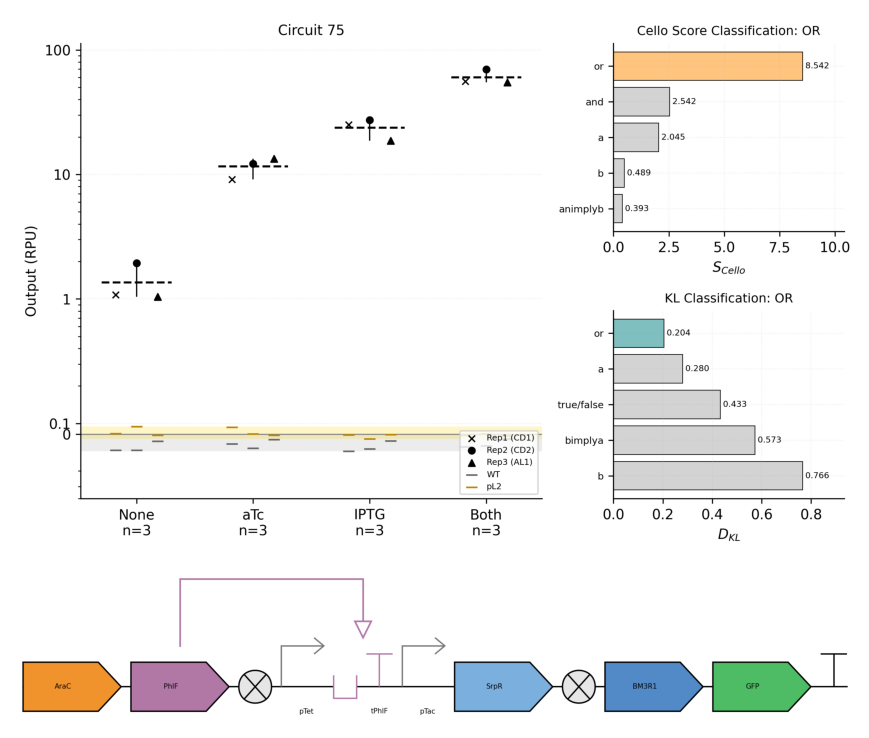

In [9]:
# drawn at FIGURE_DPI rather than PNG_DPI, so the stored preview stays small
preview = Image.open(CLASSIFY_SBOL_DIR / f"classify_circuit_{CIRCUIT:02d}_sbol.png")
figure, ax = plt.subplots(figsize=(preview.width / PNG_DPI, preview.height / PNG_DPI))
ax.imshow(preview)
ax.axis("off")
figure.subplots_adjust(left=0, right=1, top=1, bottom=0)